# World Values Survey

## Датасет — 7-я волна World Values Survey: 97 220 респондентов из 66 стран

## 1. Средние / Отклонение / Максимумы / Минимумы

In [1]:
import numpy as np
import pandas as pd

df = pd.read_csv("wvs_src.csv") # с пропусками
mask = df.iloc[1:, 1:] < 0
df[mask] = np.nan

stats = pd.DataFrame(columns=['параметр', 'count', 'mean', 'std', 'min', 'max'])
for i in range(36):
    stats.loc[i]=[f"{df.columns[i+1]}", df.iloc[1:, i+1].count(), df.iloc[1:, i+1].mean(), df.iloc[1:, i+1].std(), df.iloc[1:, i+1].min(), df.iloc[1:, i+1].max()]

stats = stats.drop([3, 4, 6, 7, 8, 9, 17, 18, 19, 20, 25, 26, 29, 30, 31, 32, 33, 34])

stats = stats.reset_index(drop=True)

stats.to_csv('stats_wvs.csv', index=False)
df.to_csv('wvs.csv', index=False) # отрицательные значения заменены на пропуски. далее работаем с этим файлом

display(stats)

,параметр,count,mean,std,min,max
0,Gender,97124,1.526430,0.499304,1.0,2.0
1,Age,96708,43.177472,16.582871,16.0,103.0
2,Household_size,96234,4.024711,2.568843,1.0,63.0
3,Number_of_children,92363,1.771900,1.719574,0.0,24.0
4,Social_class,91672,3.242200,0.978321,1.0,5.0
5,Goal_make_parents_proud,95543,1.651853,0.744989,1.0,4.0
6,Happiness,96568,1.854061,0.706805,1.0,4.0
7,Health_satisfaction,96952,2.189950,0.875517,1.0,5.0
8,Freedom_of_choice,96302,7.214056,2.259417,1.0,10.0
9,Life_satisfaction,96699,7.062100,2.239026,1.0,10.0


Вывод: благополучие и удовлетворенность безопасностью, финансами, здоровьем в основном смещена в положительную сторону. Некоторые шкалы перевернуты и самый положительный ответ там это единица.

## 2. KDE / Ядерные оценки

Построение непрерывного распределения по дискретному

"Secular values index" - инедкс секулярных ценностей Вельцеля (от традиционных взглядов к секулярным).

"Emancipative values index" - индекс эмансипативных ценностей Вельцеля (от следования коллективным нормам к личной автономии и свободе выбора).

"Income scale" - субъективная шкала уровня доходов. Распределение почти симметричное.

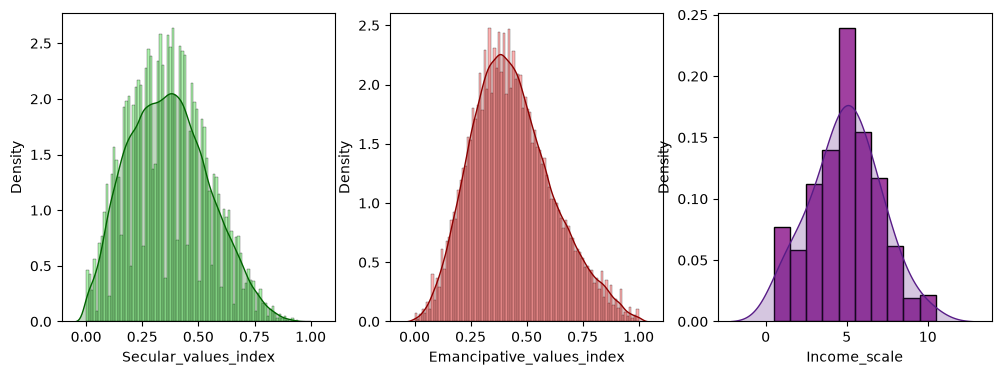

In [2]:
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns

df = pd.read_csv("wvs.csv")

fig, axes = plt.subplots(1, 3, figsize = (12, 4))

sns.histplot(data=df, x="Secular_values_index", ax=axes[0], color="#90EE90", stat="density")
sns.kdeplot(data=df, x="Secular_values_index", ax=axes[0], fill=True, color="#006400")
sns.histplot(data=df, x="Emancipative_values_index", ax=axes[1], color="#FF9999", stat="density")
sns.kdeplot(data=df, x="Emancipative_values_index", ax=axes[1], fill=True, color="#8B0000")
sns.histplot(data=df, x="Income_scale", ax=axes[2], binwidth=1, color="purple", discrete=True, stat="density")
sns.kdeplot(data=df, x="Income_scale", ax=axes[2], fill=True, bw_adjust=5, color="#581C87")
plt.show()

## 3. Cdplot / Dotplot / Boxplot

3.1 Cdplot (графики условных плотностей).

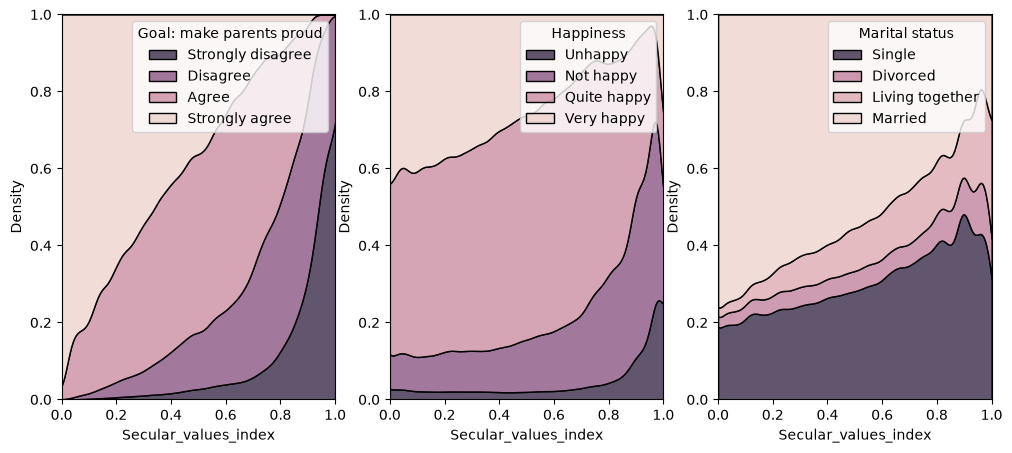

In [5]:
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 

df = pd.read_csv("wvs.csv")

mask2 = (df["Marital_status"] > 5) | (df["Marital_status"] < 4)
df2 = df[mask2]

fig, axes = plt.subplots(1, 3, figsize = (12,5))

axes[0] = sns.kdeplot(data=df, x="Secular_values_index", ax=axes[0], hue="Goal_make_parents_proud", multiple="fill", clip=(0, 1)) # more value - more satis
axes[0].legend(title="Goal: make parents proud", labels=["Strongly disagree", "Disagree", "Agree", "Strongly agree"], loc="upper right")

axes[1] = sns.kdeplot(data=df, x="Secular_values_index", ax=axes[1], hue="Happiness", multiple="fill", clip=(0, 1)) # less value - more happy
axes[1].legend(title="Happiness",labels=["Unhappy", "Not happy", "Quite happy", "Very happy"], loc="upper right")

axes[2] = sns.kdeplot(data=df2, x="Secular_values_index", ax=axes[2], hue="Marital_status", multiple="fill", clip=(0, 1))
axes[2].legend(title="Marital status", labels=["Single", "Divorced", "Living together", "Married"], loc="upper right")

plt.show()

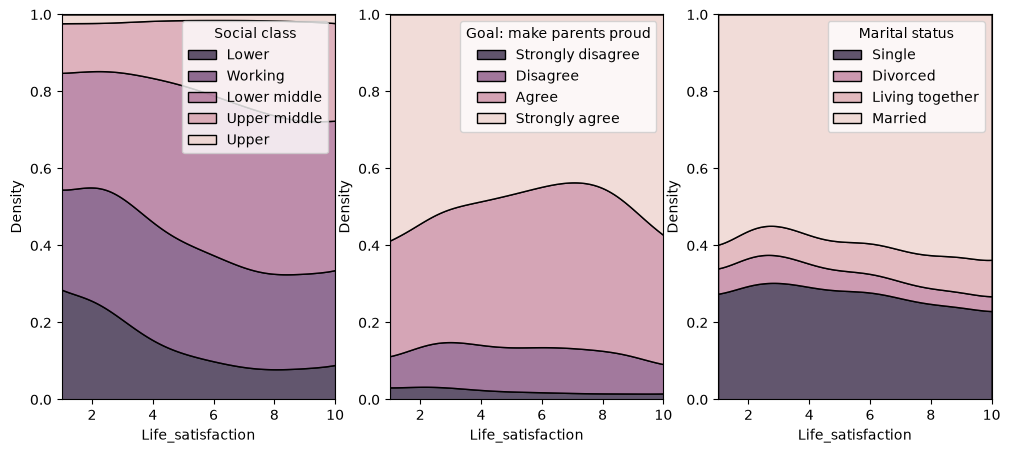

In [6]:
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 

df = pd.read_csv("wvs.csv")

fig, axes = plt.subplots(1, 3, figsize = (12,5))
mask2 = (df["Marital_status"] > 5) | (df["Marital_status"] < 4)
df2 = df[mask2]

axes[0] = sns.kdeplot(data=df, x="Life_satisfaction", ax=axes[0], hue="Social_class", multiple="fill",  bw_adjust=4, clip=(1, 10))
axes[0].legend(title="Social class", labels=["Lower", "Working", "Lower middle", "Upper middle", "Upper"], loc="upper right")

axes[1] = sns.kdeplot(data=df, x="Life_satisfaction", ax=axes[1], hue="Goal_make_parents_proud", multiple="fill", bw_adjust=4, clip=(1,10))
axes[1].legend(title="Goal: make parents proud", labels=["Strongly disagree", "Disagree", "Agree", "Strongly agree"], loc="upper right")

axes[2] = sns.kdeplot(data=df2, x="Life_satisfaction", ax=axes[2], hue="Marital_status", multiple="fill", bw_adjust=4, clip=(1, 10))
axes[2].legend(title="Marital status", labels=["Single", "Divorced", "Living together", "Married"], loc="upper right")

plt.show()

3.2 Одномерные точечные диаграммы.

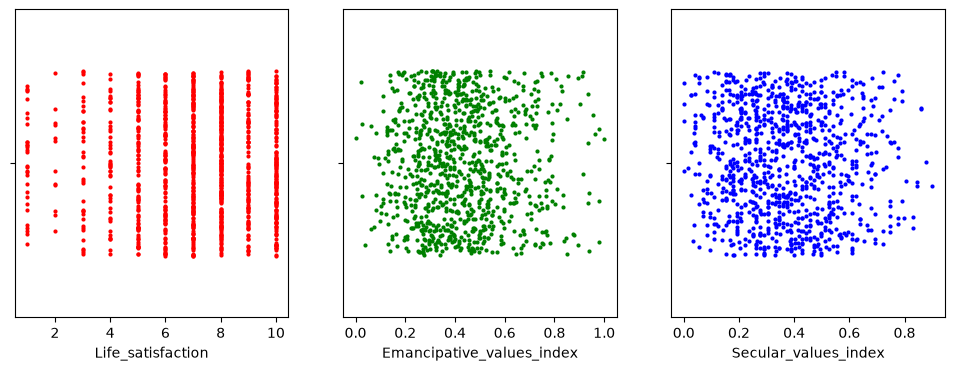

In [7]:
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns 

df = pd.read_csv("wvs.csv")
df_sample = df.sample(n=1000)

fig, axes = plt.subplots(1, 3, figsize=(12,4))
sns.stripplot(data=df_sample, size=3, jitter=0.3, x="Life_satisfaction", color="red", ax=axes[0])
sns.stripplot(data=df_sample, size=3, jitter=0.3, x="Emancipative_values_index", color="green", ax=axes[1])
sns.stripplot(data=df_sample, size=3, jitter=0.3, x="Secular_values_index", color="blue", ax=axes[2])
plt.show()

3.3 Boxplot показывает медиану, межквартильные размахи и выбросы.

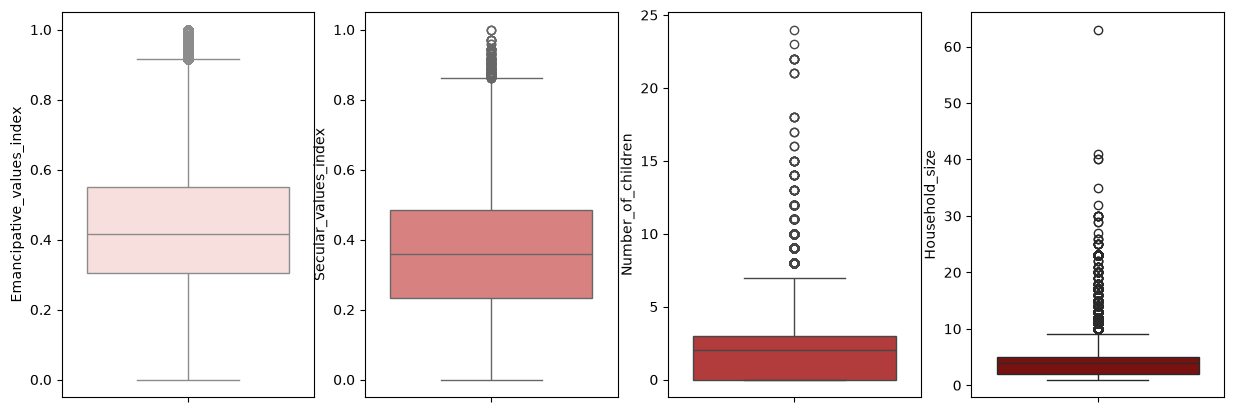

In [6]:
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns 

df = pd.read_csv("wvs.csv")

fig, axes = plt.subplots(1,4, figsize = (15, 5))

axes[0] = sns.boxplot(data=df, y="Emancipative_values_index", ax=axes[0], color="#FADBD8")
axes[1] = sns.boxplot(data=df, y="Secular_values_index", ax=axes[1], color="#E57373")
axes[2] = sns.boxplot(data=df, y="Number_of_children", ax=axes[2], color="#C62828")
axes[3] = sns.boxplot(data=df, y="Household_size", ax=axes[3], color="#8B0000")
plt.show()

Вывод: Как видно из графиков доля имеющих целью гордость родителей падает с ростом секулярности. Среди менее светских людей также больше людей считающих себя скорее счастливыми, чем несчастными, при этом доля очень несчастных почти не меняется. Среди более светских людей больше одиноких и разведенных. Наиболее вероятное объяснение: традиционные ценности напрямую связаны с семейными, поэтому люди с менее секулятивными взглядами склонны к более серьезному отношению к браку и родителям. Также люди с более секулятивными взглядами имеют меньшую зависимость субъективной удовлетворенности жизнью от семейных ценностей, поэтому они, вероятно, более открыто говорят о состоянии собственного благополучия. 

Как можно видеть субъективная удовлетворенность жизнью тесно связана с принадлежностью к социальным классам: представители низкого социального класса чаще оценивают свою жизнь как менее удовлетворительную, доля же более высоких социальных классов растет вместе с удовлетворенностью жизнью. Цель "быть гордостью родителей" - падает с удовлетворительностью жизнью, но немного поднимается при крайних значениях удовлетворенности жизнью. Неизвестно связано ли это с эффектом выбора крайнего ответа или с тем фактом что люди с высокой удовлетворенностью жизни чаще все же считают, что родители ими гордятся. Среди менее удовлетворенных жизнью также чуть больше одиноких и разведенных, но связь не такая сильная как могло интуитивно показаться.

По stripplot видно, выборка из имеющих секулярные взгляды сдвинута влево. Выборка из людей удовлетворенных жизнью смещена вправо - люди склонны оценивать свою жизнь благополучной.

На boxplot мы можем заметить, что выбросы сосредоточены в основном в верхних значениях, так-как все признаки имеют нижний предел в виде нуля, но не имеют верхнего предела.

## 4. Проверка наблюдений на наличие выбросов

4.1 Критерий Граббса для параметров имеющих плотность похожую на нормальное распределение.

In [9]:
import numpy as np 
import pandas as pd  
import scipy.stats as stats   

df = pd.read_csv("wvs.csv")

def Grabbs_method_max(df, s): # True - наблюдение является выбросом
    a_max = df[s].max()
    a = df[s].mean()
    std = df[s].std()
    n = df[s].count()
    G = (a_max - a) / std
    q = 1-(0.05/(2*n))
    t = stats.t.ppf(q, n-2)
    G_k = (n-1)/np.sqrt(n)*np.sqrt((t**2)/(n-2+t**2))
    return G > G_k

def Grabbs_method_min(df, s):
    a_min = df[s].min()
    a = df[s].mean()
    std = df[s].std()
    n = df[s].count()
    G = (a - a_min) / std
    q = 1-(0.05/(2*n))
    t = stats.t.ppf(q, n-2)
    G_k = ((n-1)/np.sqrt(n)) * np.sqrt((t**2)/(n-2+t**2))
    return G > G_k

f = ["Emancipative_values_index", "Secular_values_index", "Age", "Household_size", "Number_of_children"]

df_g = pd.DataFrame({
    "name": f,
    "выброс (максимум)": [Grabbs_method_max(df, f[0]), Grabbs_method_max(df, f[1]), Grabbs_method_max(df, f[2]), Grabbs_method_max(df, f[3]), Grabbs_method_max(df, f[4])],
    "выброс (минимум)": [Grabbs_method_min(df, f[0]), Grabbs_method_min(df, f[1]), Grabbs_method_min(df, f[2]), Grabbs_method_min(df, f[3]), Grabbs_method_min(df, f[4])]
})

display(df_g)

,name,выброс (максимум),выброс (минимум)
0,Emancipative_values_index,False,False
1,Secular_values_index,False,False
2,Age,False,False
3,Household_size,True,False
4,Number_of_children,True,False


4.2 Q-тест Диксона. Тест рассчитан на маленькие выборки, поэтому берём подвыборку из 20 наблюдений.

In [10]:
import pandas as pd 

df = pd.read_csv("wvs.csv")

df = df.dropna()
df = df.sample(20, random_state=42)

def q_test_max(s):
    s=s.sort_values()
    s=s.reset_index(drop=True)
    n=s.count()
    Q = (s.iloc[n-1]-s.iloc[n-2])/(s.iloc[n-1]-s.iloc[0])
    Q_k = 0.342 # for n = 20
    return Q > Q_k


def q_test_min(s):
    s=s.sort_values()
    s=s.reset_index(drop=True)
    n=s.count()
    Q = (s.iloc[1]-s.iloc[0])/(s.iloc[n-1]-s.iloc[0])
    Q_k = 0.342
    return Q > Q_k

f = ["Emancipative_values_index", "Secular_values_index", "Number_of_children", "Household_size"]

df_q = pd.DataFrame({
    "name": f,
    "выброс (максимум)": [q_test_max(df[f[0]]), q_test_max(df[f[1]]), q_test_max(df[f[2]]), q_test_max(df[f[3]])],
    "выброс (минимум)": [q_test_min(df[f[0]]), q_test_min(df[f[1]]), q_test_min(df[f[2]]), q_test_min(df[f[3]])]
})

display(df_q)

,name,выброс (максимум),выброс (минимум)
0,Emancipative_values_index,True,False
1,Secular_values_index,False,False
2,Number_of_children,False,False
3,Household_size,False,False


Вывод: критерий Грабсса не обнаружил выбросов для индексов секулятивности, эмансипативности, возраста, но обнаружил для размера домохозяйства и количества детей. Выбросы там действительно есть, но так-как он предполагает нормальность и признаки слишком дискретные интерпретировать результаты можно только для индексов и возраста.

По тесту Диксона выбросом оказался только максимум эмансипативного значения, но конкретный результат зависит больше от подвыборки, в которую редкий выброс может и вовсе не попасть. Так например при смене сида для sample мы получим уже другие результаты.

4.3 Межквартильный размах и Z-оценка.

In [11]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns 

df = pd.read_csv("wvs.csv")
n = 10000
df2 = df.sample(n, random_state=42)

def z_value_max(df, s):
    a_max = df[s].max()
    a = df[s].mean()
    std = df[s].std()
    n = df[s].count()
    Z = (a_max - a) / std
    return Z>3 # на 3 стандартных отклонения


def z_value_min(df, s):
    a_min = df[s].min()
    a = df[s].mean()
    std = df[s].std()
    n = df[s].count()
    Z = (a - a_min) / std
    return Z>3


def z_value_test(df, s):
    a = df[s].mean()
    std = df[s].std()
    mask = (np.abs((df[s]-a)/std)) > 3
    return df[mask]


def iqr_test(df, s):
    q1 = df[s].quantile(0.25)
    q3 = df[s].quantile(0.75)
    iqr = q3 - q1
    L = q1 - iqr*1.5
    U = q3 + iqr*1.5
    mask = (df[s]<L) | (df[s]>U) # все что не попало в нижнюю и верхнюю границы
    return df[mask]

f = ["Emancipative_values_index", "Secular_values_index", "Number_of_children", "Household_size"]


def z_value_list(df, names):
    l = []
    for name in names:
        l.append(z_value_test(df, name)[name].count())
    return l

def iqr_test_list(df, names):
    l = []
    for name in names:
        l.append(iqr_test(df, name)[name].count())
    return l


df_test = pd.DataFrame({
    "data": f,
    "z_test": z_value_list(df, f),
    "iqr_test": iqr_test_list(df, f)
})

display(df_test)

,data,z_test,iqr_test
0,Emancipative_values_index,135,734
1,Secular_values_index,82,183
2,Number_of_children,1557,899
3,Household_size,1598,2939


Вывод: IQR тест находит больше выбросов в среднем. Z-оценка предполагает нормальную распределенность данных, поэтому ее использование можно назвать совсем некорректным для numbers of children и household size. IQR не требует нормальности данных, поэтому его использование намного более логично для социальных данных, которые не только дискретны, но и зачастую ненормальны.

4.4 Изолирующий лес и LOF. 

,name,выбросов
0,Isolation Forest,100
1,LOF,100
2,both,22


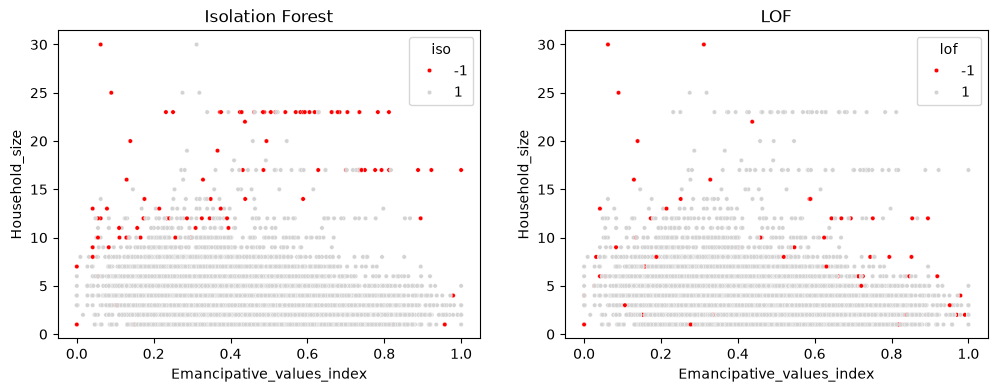

In [2]:
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns 
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("wvs.csv")

f = ["Emancipative_values_index", "Secular_values_index", "Age", "Household_size", "Number_of_children"]

df_new = df[f].dropna()
df_new = df_new.sample(n=10000, random_state=42) # на всех данных lof считается долго

scaled = StandardScaler().fit_transform(df_new) # приводим признаки к одному масштабу


def iso_forest(a):
    model = IsolationForest(contamination=0.01, random_state=42) # считаем что выбросов 1%
    return model.fit_predict(a)


def lof(a):
    model = LocalOutlierFactor(n_neighbors=30, contamination=0.01)
    return model.fit_predict(a)


df_new["iso"] = iso_forest(scaled) # -1 - выброс, 1 - нет
df_new["lof"] = lof(scaled)

mask_iso = df_new["iso"] == -1
mask_lof = df_new["lof"] == -1

data = pd.DataFrame({
    "name": ["Isolation Forest", "LOF", "both"],
    "выбросов": [mask_iso.sum(), mask_lof.sum(), (mask_iso & mask_lof).sum()]
})

display(data)

fig, axes = plt.subplots(1, 2, figsize = (12,4))

axes[0] = sns.scatterplot(data=df_new, x="Emancipative_values_index", y="Household_size", hue="iso", palette={1: "lightgray", -1: "red"}, s=10, ax=axes[0])
axes[0].set_title("Isolation Forest")

axes[1] = sns.scatterplot(data=df_new, x="Emancipative_values_index", y="Household_size", hue="lof", palette={1: "lightgray", -1: "red"}, s=10, ax=axes[1])
axes[1].set_title("LOF")

plt.show()

Вывод: эти методы смотрят на сочетания признаков и не требуют нормальности. Каждый отметил по 100 выбросов (мы сами задали 1%), но общих только 22, то есть ищут они разное. Как видно из графика, лес в основном отмечает большие домохозяйства. LOF ищет одиночные точки в разреженных местах, поэтому плотную группу одинаковых значений (например, скопление на 23 людях) он выбросом не считает.

## 5. Заполнение пропусков

5.1 Данные с реальными пропусками. Сравниваем по графикам с пропусками, а также с их заменой на средние и на медианы. В уровнях образования пропущено 36.5% значений.

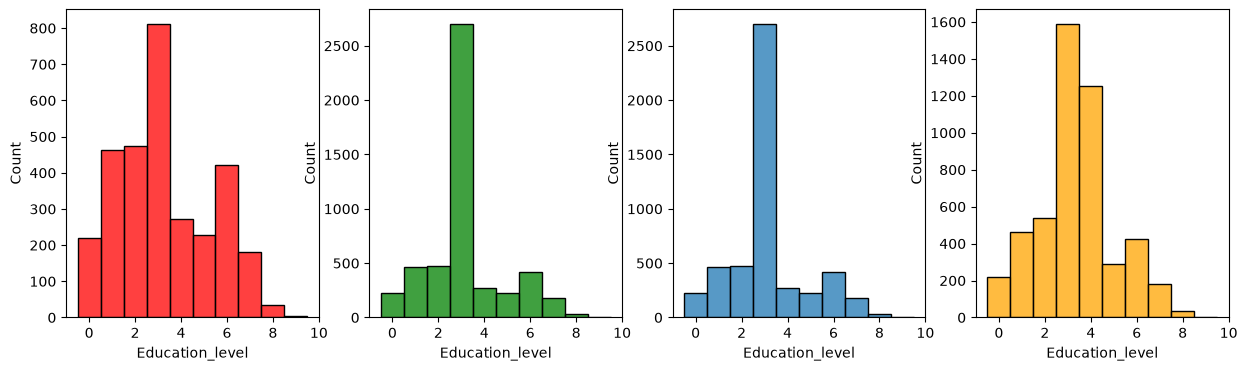

In [8]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 

def knn(df_s, df_m, s, f, k):

    x = df_m[f].fillna(df_m[f].median()) # заполнили пропуски в признаках
    x = (x - x.mean()) / x.std() 

    mask = df_m[s].isna()
    a = x[~mask].values
    b = x[mask].values
    y = df_m.loc[~mask, s].values 

    l = []
    for i in range(len(b)):
        d = np.sqrt(((a - b[i])**2).sum(axis=1)) # расстояние между теми у кого известен доход и теми кого нет
        c = np.argsort(d)[:k]
        l.append(y[c].mean()) # т.к индексы те же, потом еще усредняем

    df_m = df_m.copy()
    df_m.loc[mask, s] = l # вставили туда где пропуски
    return df_m

df = pd.read_csv("wvs.csv")
df = df.sample(5000, random_state=42)

src = df.copy()

fig, axes = plt.subplots(1, 4, figsize=(15,4))
sns.histplot(data=df, x="Education_level", binwidth=1, ax=axes[0], color="red", discrete=True)

df["Education_level"] = src["Education_level"].fillna(src["Education_level"].mean())
sns.histplot(data=df, x="Education_level", binwidth=1, ax=axes[1], color="green", discrete=True)

df["Education_level"] = src["Education_level"].fillna(src["Education_level"].median())
sns.histplot(data=df, x="Education_level", binwidth=1, ax=axes[2], discrete=True)


ff = ["Financial_satisfaction", "Social_class", "Life_satisfaction", "Age", "Household_size", "Health_satisfaction"]

df_new = knn(src, src, "Education_level", ff, 200)
sns.histplot(data=df_new, x="Education_level", binwidth=1, ax=axes[3], discrete=True, color="orange")

plt.show()

5.2 Создаем искусственные пропуски для сравнения методов заполнения (медианы против средних). На случайной подвыборке из 5000 наблюдений удалили 10% значений субъективного уровня доходов и сравнили заполнение медианой и средним по средней абсолютной ошибке MAE.

In [14]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns

df = pd.read_csv("wvs.csv")

df = df.sample(n=5000, random_state=42)
np.random.seed(42)

src = df.copy()

indexes = np.random.choice(df.index, size=500, replace=False)

df_miss = df.copy()

df_miss.loc[indexes, "Income_scale"] = np.nan


def mae_med(df_s, df_m, s):

    df_m = df_m.copy()
    df_m[s] = df_m[s].fillna(df_m[s].median())
    s = np.abs(df_m.loc[indexes, s] - df_s.loc[indexes, s]).mean()
    return s


def mae_mean(df_s, df_m, s):

    df_m = df_m.copy()
    df_m[s] = df_m[s].fillna(df_m[s].mean())
    s = np.abs(df_m.loc[indexes, s] - df_s.loc[indexes, s]).mean()
    return s


f_knn = ["Financial_satisfaction", "Social_class", "Life_satisfaction", "Age", "Household_size", "Health_satisfaction"]


def mae_knn(df_s, df_m, s, f, k):

    x = df_m[f].fillna(df_m[f].median()) # заполнили пропуски в признаках
    x = (x - x.mean()) / x.std() 

    mask = df_m[s].isna()
    a = x[~mask].values
    b = x[mask].values
    y = df_m.loc[~mask, s].values 

    l = []
    for i in range(len(b)):
        d = np.sqrt(((a - b[i])**2).sum(axis=1)) # расстояние между теми у кого известен доход и теми кого нет
        c = np.argsort(d)[:k]
        l.append(y[c].mean()) # т.к индексы те же, потом еще усредняем

    df_m = df_m.copy()
    df_m.loc[mask, s] = l # вставили туда где пропуски
    s = np.abs(df_m.loc[indexes, s] - df_s.loc[indexes, s]).mean()
    return s
    

df = pd.DataFrame({
    "names": ["median", "mean", "KNN(n=5)", "KMM(n=50)", "KNN(n=500)"],
    "MAE": [mae_med(src, df_miss, "Income_scale"), mae_mean(src, df_miss, "Income_scale"), mae_knn(src, df_miss, "Income_scale", f_knn, 5), mae_knn(src, df_miss, "Income_scale", f_knn, 50), mae_knn(src, df_miss, "Income_scale", f_knn, 500)]
})

display(df)

,names,MAE
0,median,1.539419
1,mean,1.555091
2,KNN(n=5),1.426556
3,KMM(n=50),1.325353
4,KNN(n=500),1.378394


Вывод: заполнение средним или медианой ставит одно и то же значение на место более трети данных и появляется огромный искусственный пик. KNN создает конкретно на этих данных еще один пик в соседнем значении, но в целом ошибается меньше.

Медиана дала немного меньшую ошибку, т.к медиана минимизирует именно абсолютную ошибку, а среднее — квадратичную. Оба метода не используют информацию из других признаков, поэтому ошибка у обоих большая. Использующий же больше признаков KNN при этом показывает себя лучше, но на высоких k по определению возвращается к среднему.

## 6. Проверка гипотез о нормальности. 

6.1 График квантилей (QQ-plot). Видно, что в хвостах распределения заметно отличаются от нормального. Распределение имеющее сильные выбросы также заметно отличается. Ни одно из распределений не похоже на нормальное.

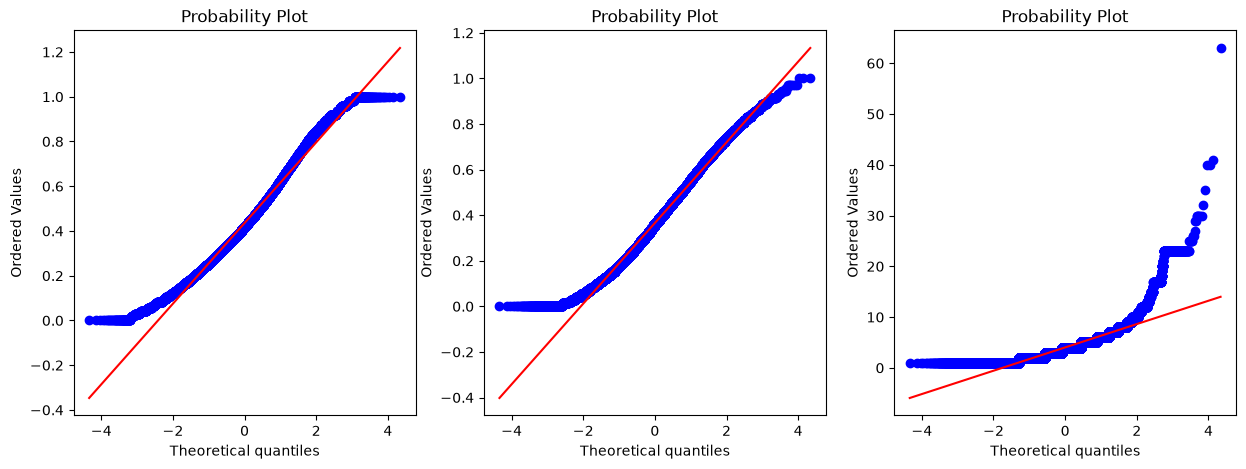

In [15]:
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 
import scipy.stats as stats 

df = pd.read_csv("wvs.csv")

fig, axes = plt.subplots(1, 3, figsize = (15,5))

stats.probplot(df["Emancipative_values_index"].dropna(), dist="norm", plot=axes[0])
stats.probplot(df["Secular_values_index"].dropna(), dist="norm", plot=axes[1])
stats.probplot(df["Household_size"].dropna(), dist="norm", plot=axes[2])

plt.show()

6.2 Метод огибающих. Точки секулятивного и эмансипативного индексов отклоняются в хвостах, Шкала доходов дискретна, поэтому образует ступечнчатую форму, поэтому проверка на нормальность является не совсем корректной.

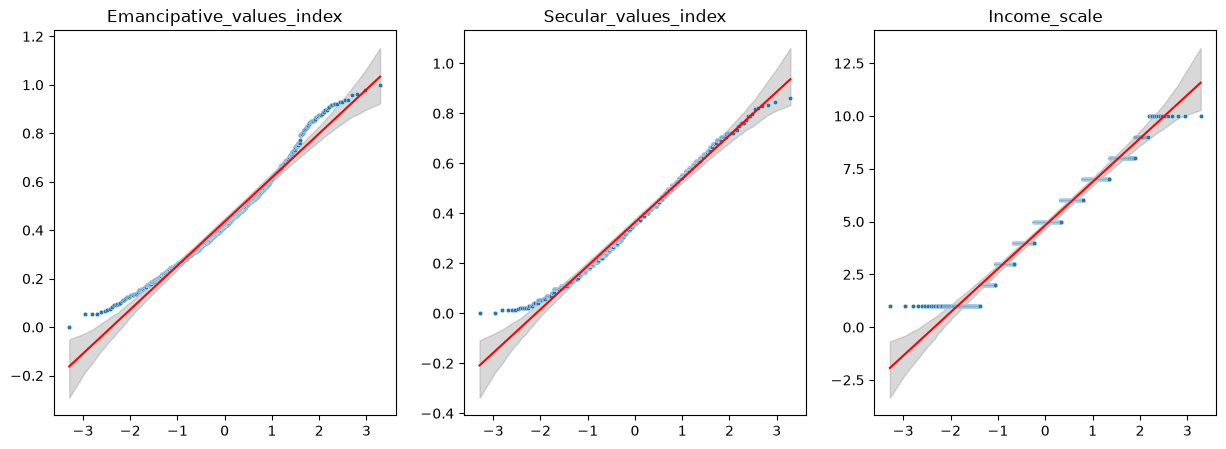

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

df = pd.read_csv("wvs.csv")
df = df.sample(1000, random_state=42)
np.random.seed(42)

def monte_carlo_envelope(df, s):
    data = df[s].dropna()
    n = data.count()
    mean = data.mean()
    std = data.std()

    a = np.zeros((1000, n)) # генерируем 1000 нормально распределенных выборок
    for i in range(1000):
        a[i] = np.random.normal(loc=mean, scale=std, size=n)

    a = np.sort(a, axis=1)

    l = np.percentile(a, 2.5, axis=0) # массив 2.5 процентилей
    u = np.percentile(a, 97.5, axis=0) # массив 97.5 процентилей

    real_sorted = np.sort(data.values)
    p = (np.arange(1, n + 1) - 0.5) / n
    theor_quantiles = stats.norm.ppf(p)

    return theor_quantiles, real_sorted, l, u


fig, axes = plt.subplots(1, 3, figsize=(15, 5))

x, y, l, u = monte_carlo_envelope(df, "Emancipative_values_index")
axes[0].fill_between(x, l, u, color="gray", alpha=0.3)
sns.scatterplot(x=x, y=y, s=10, ax=axes[0])
sns.lineplot(x=x, y=x * y.std() + y.mean(), color="red", ax=axes[0])
axes[0].set_title("Emancipative_values_index")

x, y, l, u = monte_carlo_envelope(df, "Secular_values_index")
axes[1].fill_between(x, l, u, color="gray", alpha=0.3)
sns.scatterplot(x=x, y=y, s=10, ax=axes[1])
sns.lineplot(x=x, y=x * y.std() + y.mean(), color="red", ax=axes[1])
axes[1].set_title("Secular_values_index")

x, y, l, u = monte_carlo_envelope(df, "Income_scale")
axes[2].fill_between(x, l, u, color="gray", alpha=0.3)
sns.scatterplot(x=x, y=y, s=10, ax=axes[2])
sns.lineplot(x=x, y=x * y.std() + y.mean(), color="red", ax=axes[2])
axes[2].set_title("Income_scale")

plt.show()

6.3 Критерий Колмогорова-Смирнова. Критерий Шапило-Уилка. Критерий Андресона-Дарлинга. Критерий Крамера фон Мизеса. Проверяем на разных выборках (n=30, n=300, n=3000)

n = 30

In [17]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 
import scipy.stats as stats 
import statsmodels.stats
from statsmodels.stats.diagnostic import lilliefors

df = pd.read_csv("wvs.csv")

n = 30
df = df.sample(n, random_state=42)

#fig, axes = plt.subplots(1, 3, figsize = (12,8))

def lilieford(df, s):
    s, p = lilliefors(df[s].dropna(), dist='norm')
    return s, p

def shapiro(df, s):
    s, p = stats.shapiro(df[s].dropna())
    return s, p

def cramer(df, s):
    res = stats.cramervonmises(df[s].dropna(), cdf='norm', args=(df[s].dropna().mean(), df[s].dropna().std()))
    s = res.statistic
    p = res.pvalue
    return s, p

def andersen(df, s):
    s, cv, sl = stats.anderson(df[s].dropna(), dist='norm')
    return s, cv, sl

sss = "Emancipative_values_index"

# Колмогоров-Смирнов
s_l, p_l = lilieford(df, sss)
# Шапиро
s_sh, p_sh = shapiro(df, sss)
# Крамер
s_cr, p_cr = cramer(df, sss)
# Андерсен-Дарлинг
s, cv, sl = andersen(df, sss)

data = pd.DataFrame({
    "name": ["Lillieford", "Shapiro", "Cramer", "Andersen"],
    "n": [n, n, n, n],
    "statistic": [s_l, s_sh, s_cr, s],
    "p value": [p_l, p_sh, p_cr, np.nan],
    "crit": [0.05, 0.05, 0.05, 0.75],
    "normal": [p_l>0.05, p_sh > 0.05, p_cr > 0.05, s<0.75]
})

display(data)

/tmp/ipykernel_12336/1034594232.py:31: FutureWarning: As of SciPy 1.17, users must choose a p-value calculation method by providing the `method` parameter. `method='interpolate'` interpolates the p-value from pre-calculated tables; `method` may also be an instance of `MonteCarloMethod` to approximate the p-value via Monte Carlo simulation. When `method` is specified, the result object will include a `pvalue` attribute and not attributes `critical_value`, `significance_level`, or `fit_result`. Beginning in 1.19.0, these other attributes will no longer be available, and a p-value will always be computed according to one of the available `method` options.
  s, cv, sl = stats.anderson(df[s].dropna(), dist='norm')


,name,n,statistic,p value,crit,normal
0,Lillieford,30,0.105756,0.519925,0.05,True
1,Shapiro,30,0.976764,0.734545,0.05,True
2,Cramer,30,0.047093,0.897105,0.05,True
3,Andersen,30,0.296370,NaN,0.75,True


n = 300

In [18]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 
import scipy.stats as stats 
import statsmodels.stats
from statsmodels.stats.diagnostic import lilliefors

df = pd.read_csv("wvs.csv")

n = 300
df = df.sample(n, random_state=42)

#fig, axes = plt.subplots(1, 3, figsize = (12,8))

def lilieford(df, s):
    s, p = lilliefors(df[s].dropna(), dist='norm')
    return s, p

def shapiro(df, s):
    s, p = stats.shapiro(df[s].dropna())
    return s, p

def cramer(df, s):
    res = stats.cramervonmises(df[s].dropna(), cdf='norm', args=(df[s].dropna().mean(), df[s].dropna().std()))
    s = res.statistic
    p = res.pvalue
    return s, p

def andersen(df, s):
    s, cv, sl = stats.anderson(df[s].dropna(), dist='norm')
    return s, cv, sl

sss = "Emancipative_values_index"

# Колмогоров-Смирнов
s_l, p_l = lilieford(df, sss)
# Шапиро
s_sh, p_sh = shapiro(df, sss)
# Крамер
s_cr, p_cr = cramer(df, sss)
# Андерсен-Дарлинг
s, cv, sl = andersen(df, sss)

data = pd.DataFrame({
    "name": ["Lillieford", "Shapiro", "Cramer", "Andersen"],
    "n": [n, n, n, n],
    "statistic": [s_l, s_sh, s_cr, s],
    "p value": [p_l, p_sh, p_cr, np.nan],
    "crit": [0.05, 0.05, 0.05, 0.75],
    "normal": [p_l>0.05, p_sh > 0.05, p_cr > 0.05, s<0.75]
})

display(data)

/tmp/ipykernel_12336/2990494932.py:31: FutureWarning: As of SciPy 1.17, users must choose a p-value calculation method by providing the `method` parameter. `method='interpolate'` interpolates the p-value from pre-calculated tables; `method` may also be an instance of `MonteCarloMethod` to approximate the p-value via Monte Carlo simulation. When `method` is specified, the result object will include a `pvalue` attribute and not attributes `critical_value`, `significance_level`, or `fit_result`. Beginning in 1.19.0, these other attributes will no longer be available, and a p-value will always be computed according to one of the available `method` options.
  s, cv, sl = stats.anderson(df[s].dropna(), dist='norm')


,name,n,statistic,p value,crit,normal
0,Lillieford,300,0.060858,0.016942,0.05,False
1,Shapiro,300,0.978083,0.000149,0.05,False
2,Cramer,300,0.259347,0.176824,0.05,True
3,Andersen,300,1.647062,NaN,0.75,False


n= 3000

In [19]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 
import scipy.stats as stats 
import statsmodels.stats
from statsmodels.stats.diagnostic import lilliefors

df = pd.read_csv("wvs.csv")

n = 3000
df = df.sample(n, random_state=42)

#fig, axes = plt.subplots(1, 3, figsize = (12,8))

def lilieford(df, s):
    s, p = lilliefors(df[s].dropna(), dist='norm')
    return s, p

def shapiro(df, s):
    s, p = stats.shapiro(df[s].dropna())
    return s, p

def cramer(df, s):
    res = stats.cramervonmises(df[s].dropna(), cdf='norm', args=(df[s].dropna().mean(), df[s].dropna().std()))
    s = res.statistic
    p = res.pvalue
    return s, p

def andersen(df, s):
    s, cv, sl = stats.anderson(df[s].dropna(), dist='norm')
    return s, cv, sl

sss = "Emancipative_values_index"

# Колмогоров-Смирнов
s_l, p_l = lilieford(df, sss)
# Шапиро
s_sh, p_sh = shapiro(df, sss)
# Крамер
s_cr, p_cr = cramer(df, sss)
# Андерсен-Дарлинг
s, cv, sl = andersen(df, sss)

data = pd.DataFrame({
    "name": ["Lillieford", "Shapiro", "Cramer", "Andersen"],
    "n": [n, n, n, n],
    "statistic": [s_l, s_sh, s_cr, s],
    "p value": [p_l, p_sh, p_cr, np.nan],
    "crit": [0.05, 0.05, 0.05, 0.75],
    "normal": [p_l>0.05, p_sh > 0.05, p_cr > 0.05, s<0.75]
})

display(data)

/tmp/ipykernel_12336/3387935205.py:31: FutureWarning: As of SciPy 1.17, users must choose a p-value calculation method by providing the `method` parameter. `method='interpolate'` interpolates the p-value from pre-calculated tables; `method` may also be an instance of `MonteCarloMethod` to approximate the p-value via Monte Carlo simulation. When `method` is specified, the result object will include a `pvalue` attribute and not attributes `critical_value`, `significance_level`, or `fit_result`. Beginning in 1.19.0, these other attributes will no longer be available, and a p-value will always be computed according to one of the available `method` options.
  s, cv, sl = stats.anderson(df[s].dropna(), dist='norm')


,name,n,statistic,p value,crit,normal
0,Lillieford,3000,0.044944,1.000000e-03,0.05,False
1,Shapiro,3000,0.982898,1.598943e-18,0.05,False
2,Cramer,3000,1.992189,1.324330e-05,0.05,False
3,Andersen,3000,12.844951,NaN,0.75,False


При n = 30 ни один из критериев нормальность не отвергает, при n = 300 нормальность отвергают 3/4 критериев, при n= 3000 - все четыре. На малых выборках критерии не замечают отклонения, на больших - отвергают нормальность при наличии отклонений. 